# Laboratorul nr. 2
## Student: Jalba Oleg IASD 2601

In [20]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
data = pd.read_csv(Path("Orange_Telecom_Churn_Data.csv"))
print(data.shape, int(data.isna().sum().sum()))

(5000, 21) 0


### Exercițiul 1

In [21]:
print(data[["state","area_code","phone_number","intl_plan","voice_mail_plan"]].nunique())

state                51
area_code             3
phone_number       5000
intl_plan             2
voice_mail_plan       2
dtype: int64


**Răspuns:** `phone_number` e un identificator (≈5.000 valori unice): One-Hot ar adăuga ≈5.000 coloane (≈200 MB dens, float64), iar distanța dintre oricare două numere diferite ar fi mereu √2, deci fără semnal util. KNN ar memora exemple (overfitting). Coloanele `state`, `area_code`, `phone_number` se elimină.

### Exercițiul 2

In [22]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
c = np.array([[1., 0.], [250., 100.], [1000., 1000.]])  # ultimul = outlier
print("Fără scalare:", np.linalg.norm(c[0] - c[1]).round(1), "| contribuții:", np.abs(c[0] - c[1]))
for s in (MinMaxScaler(), StandardScaler()):
    t = s.fit_transform(c)
    print(type(s).__name__, "cu outlier:", np.linalg.norm(t[0] - t[1]).round(3))

Fără scalare: 268.3 | contribuții: [249. 100.]
MinMaxScaler cu outlier: 0.269
StandardScaler cu outlier: 0.627


**Răspuns:** fără scalare, diferența de 249 la `account_length` domină diferența de 100 la `total_day_charge`. Un outlier extinde intervalul MinMax și umflă media/deviația standard la StandardScaler; în ambele cazuri observațiile normale se comprimă și distanțele dintre ele devin mai puțin informative.

### Exercițiul 3

In [23]:
from timeit import timeit
from sklearn.neighbors import KNeighborsClassifier
rng = np.random.default_rng(42)
X = rng.random((100_000, 10)); y = rng.integers(0, 2, 100_000)
print("sklearn:", timeit(lambda: KNeighborsClassifier().fit(X, y), number=1))
try:
    from sklearnex import patch_sklearn; patch_sklearn()
    from sklearn.neighbors import KNeighborsClassifier
    print("sklearnex:", timeit(lambda: KNeighborsClassifier().fit(X, y), number=1))
except ImportError:
    print("sklearnex indisponibil")

sklearn: 0.030617166019510478
sklearnex indisponibil


**Răspuns:** `sklearnex` înlocuiește implementările din scikit-learn cu variante optimizate (oneDAL: indexare KD-Tree/Brute-force, vectorizare AVX-512, multithreading). Câștigul depinde de date și hardware.

### Exercițiul 4

1 7.0
2 5.0
inf 4.0


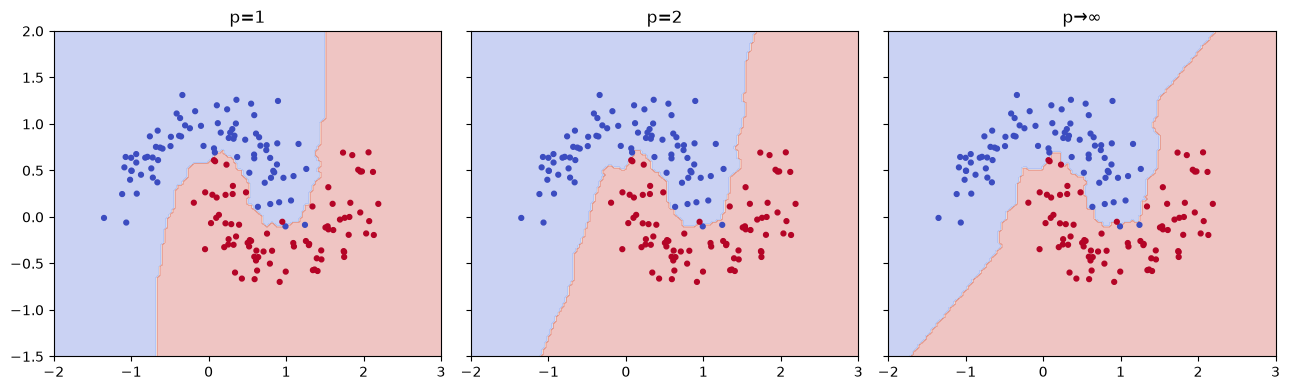

In [24]:
from sklearn.datasets import make_moons
def minkowski_distance(x, y, p):
    d = np.abs(np.asarray(x, float) - np.asarray(y, float))
    return d.max() if np.isinf(p) else (d ** p).sum() ** (1 / p)

for p in (1, 2, np.inf):
    print(p, minkowski_distance([0, 0], [3, 4], p))

X2, y2 = make_moons(160, noise=0.19, random_state=42)
xx, yy = np.meshgrid(np.linspace(-2, 3, 150), np.linspace(-1.5, 2, 150))
fig, ax = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for a, (t, kw) in zip(ax, [("p=1", dict(p=1)), ("p=2", dict(p=2)), ("p→∞", dict(metric="chebyshev"))]):
    m = KNeighborsClassifier(5, **kw).fit(X2, y2)
    a.contourf(xx, yy, m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape), alpha=.3, cmap="coolwarm")
    a.scatter(*X2.T, c=y2, s=12, cmap="coolwarm"); a.set_title(t)
plt.tight_layout(); plt.show()

**Răspuns:** p=1 însumează diferențele absolute, p=2 e euclidiană, p→∞ ia diferența maximă pe o coordonată. Schimbarea metricii schimbă vecinii și deci forma frontierei (colțuroasă la p=1 și ∞, netedă la p=2).

### Exercițiul 5

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, classification_report

X_all = data.drop(columns=["state", "area_code", "phone_number", "churned"]).copy()
for c_ in ["intl_plan", "voice_mail_plan"]:
    X_all[c_] = X_all[c_].map({"no": 0, "yes": 1}).astype(int)
y_all = data["churned"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=42)

def knn_pipeline(k, weights="uniform", p=2):
    return Pipeline([("scale", MinMaxScaler()), ("knn", KNeighborsClassifier(k, weights=weights, p=p))])

for nume, m in [("K=1", knn_pipeline(1)), ("K=3, distance", knn_pipeline(3, "distance"))]:
    m.fit(X_train, y_train)
    print(nume, "train:", accuracy_score(y_train, m.predict(X_train)),
          "test:", accuracy_score(y_test, m.predict(X_test)))

K=1 train: 1.0 test: 0.878
K=3, distance train: 1.0 test: 0.894


**Răspuns:** pe datele de antrenare, xᵢ este propriul vecin la distanța 0 și își votează propria etichetă (la `weights='distance'` distanța 0 domină votul). Rezultatul de 100% e memorare, nu generalizare; contează scorul pe test.

### Exercițiul 6

In [29]:
class CustomKNN:
    def fit(self, X, y):
        self.X_train = np.asarray(X, float)
        self.classes_, self.codes_ = np.unique(np.asarray(y), return_inverse=True)
        return self

    def predict(self, X_test, k=3):
        X_test = np.asarray(X_test, float)
        d2 = ((X_test ** 2).sum(1)[:, None] + (self.X_train ** 2).sum(1)[None, :]
              - 2 * X_test @ self.X_train.T)
        idx = np.argpartition(d2, k - 1, axis=1)[:, :k]
        voturi = np.apply_along_axis(np.bincount, 1, self.codes_[idx], minlength=len(self.classes_))
        return self.classes_[voturi.argmax(1)]

sc = MinMaxScaler().fit(X_train.iloc[:300])
Xa, Xb = sc.transform(X_train.iloc[:300]), sc.transform(X_test.iloc[:80])
ya, yb = y_train.iloc[:300].to_numpy(), y_test.iloc[:80].to_numpy()
pred = CustomKNN().fit(Xa, ya).predict(Xb, k=5)
ref = KNeighborsClassifier(5).fit(Xa, ya).predict(Xb)
print("acuratețe:", accuracy_score(yb, pred), "| concordanță sklearn:", (pred == ref).mean())

acuratețe: 0.8875 | concordanță sklearn: 1.0


**Răspuns:** distanța euclidiană (la pătrat, ordinea vecinilor e aceeași), selecție K vecini cu `argpartition`, vot majoritar.

### Exercițiul 7

K optim: 3


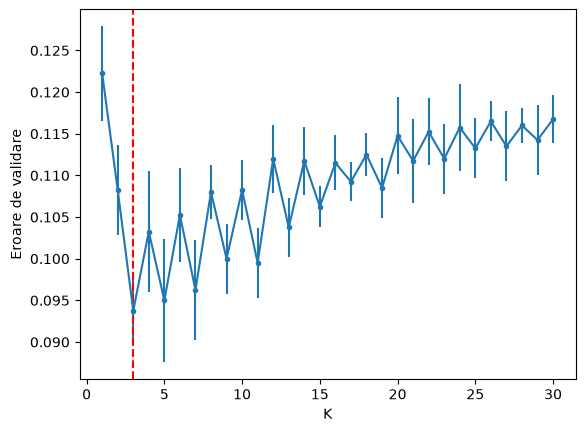

In [30]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rez = []
for k in range(1, 31):
    s = cross_val_score(knn_pipeline(k), X_train, y_train, cv=cv)
    rez.append((k, s.mean(), s.std()))
rez = pd.DataFrame(rez, columns=["K", "medie", "std"])
best_k = int(rez.sort_values(["medie", "K"], ascending=[False, True]).iloc[0]["K"])
print("K optim:", best_k)
plt.errorbar(rez.K, 1 - rez["medie"], yerr=rez["std"], marker="o", ms=3)
plt.axvline(best_k, ls="--", c="r"); plt.xlabel("K"); plt.ylabel("Eroare de validare"); plt.show()

**Răspuns:** K se alege doar pe setul de antrenare (cu scalerul reantrenat în fiecare fold); testul rămâne pentru evaluarea finală.

### Exercițiul 8

In [31]:
y_pred = knn_pipeline(best_k).fit(X_train, y_train).predict(X_test)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=["fără churn", "churn"], zero_division=0))
print("baseline (mereu fără churn):", (1 - y_test.mean()).round(3))

[[834  25]
 [ 81  60]]
              precision    recall  f1-score   support

  fără churn       0.91      0.97      0.94       859
       churn       0.71      0.43      0.53       141

    accuracy                           0.89      1000
   macro avg       0.81      0.70      0.74      1000
weighted avg       0.88      0.89      0.88      1000

baseline (mereu fără churn): 0.859


**Răspuns:** un model care prezice mereu „fără churn” are acuratețe mare, dar recall 0 pentru clienții care pleacă. Precision, recall și F1 pe clasa churn sunt metricile relevante.

### Exercițiul 9

In [32]:
y_z = np.array([0, 0, 0, 0, 1])
clean = np.array([[.2, 0], [-.2, 0], [0, .2], [0, -.2], [2, 2]])
noisy = clean.copy(); noisy[-1] = [.005, 0]   # outlier lângă interogare
q = np.array([[0., 0.]])
for nume, P in [("fără zgomot", clean), ("cu zgomot", noisy)]:
    for w in ("uniform", "distance"):
        m = KNeighborsClassifier(5, weights=w).fit(P, y_z)
        print(nume, w, "→", m.predict(q)[0], "P(1)=", m.predict_proba(q)[0, 1].round(3))

fără zgomot uniform → 0 P(1)= 0.2
fără zgomot distance → 0 P(1)= 0.017
cu zgomot uniform → 0 P(1)= 0.2
cu zgomot distance → 1 P(1)= 0.909


**Răspuns:** `distance` e mai vulnerabil la un punct anormal foarte apropiat de interogare (1/d foarte mare îl face să domine votul); `uniform` rămâne 4–1.

### Exercițiul 10

In [36]:
g = np.random.default_rng(42)
for n in (0, 10, 30, 80):
    tr, te = X_train.copy(), X_test.copy()
    for i in range(n):
        tr[f"z{i}"] = g.random(len(tr)); te[f"z{i}"] = g.random(len(te))
    p = knn_pipeline(best_k).fit(tr, y_train).predict(te)
    print(n, "acc:", accuracy_score(y_test, p), "F1:", f1_score(y_test, p, zero_division=0))

0 acc: 0.894 F1: 0.5309734513274337
10 acc: 0.867 F1: 0.2962962962962963
30 acc: 0.851 F1: 0.15819209039548024
80 acc: 0.837 F1: 0.11891891891891893


**Răspuns:** fiecare coloană aleatorie adaugă termeni irelevanți în distanță, iar diferențele utile dintre clienți se pierd; F1 pentru churn scade pe măsură ce crește dimensionalitatea.

### Exercițiul 11

In [38]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error
Xr, yr = data[["total_day_minutes", "total_day_calls"]], data["total_day_charge"]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=42)
for k in (1, 3, 5, 9, 15, 30):
    m = Pipeline([("s", MinMaxScaler()), ("r", KNeighborsRegressor(k))]).fit(Xr_tr, yr_tr)
    print(k, "MSE:", mean_squared_error(yr_te, m.predict(Xr_te)))

1 MSE: 1.1926488
3 MSE: 1.0103340888888892
5 MSE: 0.641112332
9 MSE: 0.6463955419753086
15 MSE: 0.8709128337777782
30 MSE: 1.129665375


**Răspuns:** regresorul face media valorilor vecinilor (clasificatorul votează). Aici `total_day_charge` e aproape determinist din minute, deci MSE e mic; K prea mare netezește excesiv.

### Exercițiul 12

In [41]:
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import SelectKBest, f_classif
pipe = Pipeline([("scale", MinMaxScaler()), ("select", "passthrough"), ("knn", KNeighborsClassifier())])
comun = {"knn__n_neighbors": [3, 5, 7, 9, 11], "knn__weights": ["uniform", "distance"], "knn__p": [1, 2]}
grila = [{"select": ["passthrough"], **comun}, {"select": [SelectKBest(f_classif, k=10)], **comun}]
gs = GridSearchCV(pipe, grila, cv=cv, scoring="f1").fit(X_train, y_train)
p = gs.predict(X_test)
print(gs.best_params_, "| F1 validare:", round(gs.best_score_, 4))
print("Test → F1:", f1_score(y_test, p), "acc:", accuracy_score(y_test, p),
      "precision:", precision_score(y_test, p, zero_division=0), "recall:", recall_score(y_test, p))

{'knn__n_neighbors': 5, 'knn__p': 2, 'knn__weights': 'uniform', 'select': SelectKBest()} | F1 validare: 0.6561
Test → F1: 0.5974025974025974 acc: 0.907 precision: 0.7666666666666667 recall: 0.48936170212765956


**Răspuns:** scalerul și selectorul sunt în pipeline, deci se ajustează separat în fiecare fold; scorul F1 e mai informativ decât acuratețea pe clase dezechilibrate.